# GGA 990 — Assignment 3: Land Use and Land Cover Classification of Benin City, Edo State
**Student:** Osaigbovo Onaiwu-Nzegwu (41269) · **Lecturer:** Dr. Jude A. Adeleke · ISSE, AUST Abuja

Follows the Part 3 class practical (Section 7): **Part A** classifies a Sentinel-2 composite in Earth Engine, **Part B** compares Random Forest and SVM and tests spatial cross-validation in scikit-learn, and **Part C** tries unsupervised k-means. The final map, area table and interpretation follow.

**How to use:** set your project ID in Step 0, run down to Step 2c, check the samples on the map, fill in `CORRECTIONS`, then *Runtime → Restart session and run all*.

## Step 0: Setup and connection to Earth Engine

In [ ]:
!pip install geemap --quiet

import io
import ee
import geemap
import folium
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from PIL import Image

PROJECT_ID = "ee-yourname"     # <-- replace with YOUR Cloud project ID
ee.Authenticate()
ee.Initialize(project="isse-narsda-training-project")
print(ee.String("Earth Engine is ready").getInfo())

Earth Engine is ready


# Part A: Classification in Earth Engine

## Step 1: Build the feature stack
The study area is a 0.19° × 0.19° rectangle (about 21 km × 21 km) covering Benin City and its urban fringe: the city core around the King's Square (Ring Road), Ugbowo, Ikpoba Hill, Sapele Road and the forest and farmland at the edges.

The composite covers the **2025–26 dry season** (November to February), when cloud cover in southern Nigeria is lowest. Cloud and shadow pixels are removed with the SCL band and the median is taken. Four spectral indices are added as features: NDVI, NDWI, MNDWI and NDBI.

In [ ]:
CITY = "Benin City, Edo State"
aoi = ee.Geometry.Rectangle([5.53, 6.24, 5.72, 6.43])   # west, south, east, north
START, END = "2025-11-01", "2026-03-01"                  # dry season
CLOUD_MAX = 30                                           # scene-level cloud filter (%)


def mask_clouds(img):
    """Remove cloud and shadow pixels (SCL 3, 8, 9, 10) and convert to reflectance (0-1)."""
    scl = img.select("SCL")
    clear = scl.neq(3).And(scl.neq(8)).And(scl.neq(9)).And(scl.neq(10))
    return img.updateMask(clear).divide(10000)


col = (ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
       .filterBounds(aoi)
       .filterDate(START, END)
       .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", CLOUD_MAX)))
n_images = col.size().getInfo()
print(n_images, "Sentinel-2 images used in the composite")
if n_images < 3:
    print("Few images: raise CLOUD_MAX to 50 and rerun this cell.")

img = col.map(mask_clouds).median().clip(aoi)

ndvi = img.normalizedDifference(["B8", "B4"]).rename("NDVI")      # vegetation
ndwi = img.normalizedDifference(["B3", "B8"]).rename("NDWI")      # open water
mndwi = img.normalizedDifference(["B3", "B11"]).rename("MNDWI")   # water, separates it from built-up
ndbi = img.normalizedDifference(["B11", "B8"]).rename("NDBI")     # built-up / bare
stack = ee.Image.cat([img.select(["B2", "B3", "B4", "B8", "B11", "B12"]), ndvi, ndwi, mndwi, ndbi])
feature_names = stack.bandNames().getInfo()
print(feature_names)

14 Sentinel-2 images used in the composite
['B2', 'B3', 'B4', 'B8', 'B11', 'B12', 'NDVI', 'NDWI', 'MNDWI', 'NDBI']


## Step 2: Get labelled samples
Labels come from **ESA WorldCover 2021** (10 m), merged into five classes. Up to 300 points per class are drawn with stratified sampling, so small classes such as water are not swamped by large ones.

In [ ]:
# 0 Water, 1 Built-up, 2 Trees, 3 Grassland/Cropland, 4 Bare soil
NAMES = ["Water", "Built-up", "Trees", "Grass/Crop", "Bare soil"]
PALETTE = ["0000ff", "ff0000", "006400", "c8e632", "d2b48c"]
NAME_TO_ID = {n: i for i, n in enumerate(NAMES)}

wc = ee.ImageCollection("ESA/WorldCover/v200").first().select("Map")
labels = wc.remap([80, 50, 10, 20, 30, 40, 60],
                  [0, 1, 2, 3, 3, 3, 4]).rename("landcover")

samples = stack.addBands(labels).stratifiedSample(
    numPoints=300, classBand="landcover", region=aoi,
    scale=10, seed=42, geometries=True)

# Bring the samples (with coordinates) into a pandas table
rows = samples.getInfo()["features"]
df = pd.DataFrame([{**r["properties"],
                    "lon": r["geometry"]["coordinates"][0],
                    "lat": r["geometry"]["coordinates"][1]} for r in rows])
df = df.dropna(subset=feature_names).reset_index(drop=True)
df["sid"] = df.index                                  # sample ID used in the checking step
df["worldcover_label"] = df["landcover"].map(dict(enumerate(NAMES)))
print(df["worldcover_label"].value_counts())

worldcover_label
Water         300
Built-up      300
Trees         300
Grass/Crop    300
Bare soil     300
Name: count, dtype: int64


## Step 2b: Check samples against high-resolution imagery
WorldCover is from 2021 and has its own errors, and Benin City has grown since then. **20 samples per class** are shown on high-resolution satellite imagery. Each point is coloured by its WorldCover label; hover to see its ID and label, and zoom in to check it.

**What to do:**
1. Open the map below. Use the layer control (top right) to view one class at a time.
2. Zoom to each point and decide whether the label is right for what you see.
3. Write every wrong one in `CORRECTIONS` in the next cell: `sid: "Correct class"`, or `sid: None` to remove a point you cannot decide on (mixed pixel, cloud, imagery too blurry).

The basemap may be a few years older or newer than the 2025–26 composite. Where in doubt, also switch on the *True colour 2025-26* layer.

In [ ]:
CHECK_PER_CLASS = 20
check = pd.concat([g.sample(min(len(g), CHECK_PER_CLASS), random_state=1)
                   for _, g in df.groupby("landcover")])
check = check.sort_values(["landcover", "sid"])
check[["sid", "worldcover_label", "lon", "lat"]].to_csv("samples_to_check.csv", index=False)

# True-colour composite tiles for comparison
tc_url = img.getMapId({"bands": ["B4", "B3", "B2"], "min": 0, "max": 0.3})["tile_fetcher"].url_format

w, s, e, n = 5.53, 6.24, 5.72, 6.43
cm = folium.Map(location=[(s + n) / 2, (w + e) / 2], zoom_start=12, tiles=None)
folium.TileLayer("https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
                 attr="Esri World Imagery", name="High-resolution imagery (Esri)", max_zoom=19).add_to(cm)
folium.TileLayer(tc_url, attr="Copernicus Sentinel-2 via Google Earth Engine",
                 name="True colour 2025-26", overlay=True, show=False).add_to(cm)
for cls, grp in check.groupby("worldcover_label"):
    layer = folium.FeatureGroup(name=f"{cls} ({len(grp)})")
    colour = "#" + PALETTE[NAME_TO_ID[cls]]
    for _, r in grp.iterrows():
        folium.CircleMarker([r.lat, r.lon], radius=6, color="white", weight=2,
                            fill=True, fill_color=colour, fill_opacity=1,
                            tooltip=f"#{r.sid}: {cls}").add_to(layer)
    layer.add_to(cm)
folium.LayerControl(collapsed=False).add_to(cm)
cm.save("sample_check_map.html")
cm

In [ ]:
# Fill in after checking. Use the class names exactly: Water, Built-up, Trees, Grass/Crop, Bare soil
# Example:  CORRECTIONS = {12: "Built-up", 305: "Grass/Crop", 771: None}
CORRECTIONS = {
    # Water (4 of 20 wrong)
    242: "Bare soil",    # sandy bank, not water
    213: None,           # mixed pixel: half water, half bank
    266: None,           # mixed pixel: half water, half bank
    11: "Grass/Crop",    # grassy bank, not water
    # Trees (19 of 20 wrong)
    813: "Grass/Crop",   # grassland with low grasses/shrubs
    629: "Bare soil",    # bare ground
    767: "Grass/Crop",   # grassland with low grasses/shrubs
    785: "Grass/Crop",   # grassland with low grasses/shrubs
    875: "Bare soil",    # bare ground beside a building
    747: "Built-up",     # building top
    678: "Grass/Crop",   # grassland with low grasses/shrubs
    789: "Built-up",     # building top
    899: "Grass/Crop",   # grassland with low grasses/shrubs
    611: "Grass/Crop",   # grassland with low grasses/shrubs
    658: "Built-up",     # building top
    722: "Grass/Crop",   # grassland with low grasses/shrubs
    866: "Grass/Crop",   # bushy plants (shrubs belong to Grass/Crop in this scheme)
    842: "Grass/Crop",   # grassland with low grasses/shrubs
    673: "Grass/Crop",   # grassland with low grasses/shrubs
    706: "Grass/Crop",   # grassland with low grasses/shrubs
    820: "Bare soil",    # bare ground
    776: "Grass/Crop",   # grassland with low grasses
    727: "Grass/Crop",   # bushy grassland with low grasses/shrubs
    # Grass/Crop (5 of 20 wrong)
    973: "Bare soil",    # earth road / bare ground beside grassland
    1089: "Built-up",    # uncompleted building
    1027: "Bare soil",   # bare ground
    1166: None,          # very sparse grass: unclear between grass and bare
    1022: "Bare soil",   # bare ground
    # Built-up (7 of 20 wrong)
    489: "Bare soil",    # bare ground / earth road in built-up area
    378: "Bare soil",    # bare ground in built-up area
    520: "Grass/Crop",   # bushy area in built-up area
    476: "Grass/Crop",   # bushy area in built-up area
    406: "Bare soil",    # bare ground in built-up area
    467: "Bare soil",    # bare ground / earth road in built-up area
    599: "Grass/Crop",   # bushy area in built-up area
    # Bare soil (6 of 20 wrong)
    1229: None,          # right beside a building: mixed pixel
    1347: None,          # green field or algae-covered lake: cannot tell
    1258: "Grass/Crop",  # grassy patch inside bare area
    1499: None,          # slightly grassy: unclear between grass and bare
    1475: None,          # green field or algae-covered lake: cannot tell
    1211: "Grass/Crop",  # grassland
}

bad = {k: v for k, v in CORRECTIONS.items() if v is not None and v not in NAMES}
assert not bad, f"Unknown class names: {bad}"

# Checking log: evidence of which samples were checked and what changed
log = check[["sid", "worldcover_label"]].copy()
log["checked_label"] = log.apply(lambda r: CORRECTIONS.get(r.sid, r.worldcover_label), axis=1)
log["status"] = np.select([log.sid.map(lambda i: i in CORRECTIONS and CORRECTIONS[i] is None),
                           log.checked_label != log.worldcover_label],
                          ["removed", "corrected"], "confirmed")
log.loc[log.status == "removed", "checked_label"] = "-"
log.to_csv("sample_checking_log.csv", index=False)

summary = pd.crosstab(log.worldcover_label, log.status).reindex(NAMES).fillna(0).astype(int)
summary["checked"] = summary.sum(axis=1)
print("Checking summary (20 samples per class checked against high-resolution imagery):")
display(summary)

# Apply corrections to the full sample table
removed = [k for k, v in CORRECTIONS.items() if v is None]
df = df[~df.sid.isin(removed)].copy()
for sid, new in CORRECTIONS.items():
    if new is not None:
        df.loc[df.sid == sid, "landcover"] = NAME_TO_ID[new]
df["label"] = df["landcover"].map(dict(enumerate(NAMES)))
print(f"{len(CORRECTIONS) - len(removed)} labels corrected, {len(removed)} samples removed")
print(df["label"].value_counts())

Checking summary (20 samples per class checked against high-resolution imagery):


status,confirmed,corrected,removed,checked
worldcover_label,,,,
Water,16,2,2,20
Built-up,13,7,0,20
Trees,1,19,0,20
Grass/Crop,15,4,1,20
Bare soil,14,2,4,20


34 labels corrected, 7 samples removed
label
Grass/Crop    314
Bare soil     305
Built-up      297
Water         296
Trees         281
Name: count, dtype: int64


In [ ]:
# Step 2b (continued): clean the UNCHECKED WorldCover labels with simple spectral rules.
# The 100 checked samples keep the labels given during checking.
print("NDVI by class before cleaning:")
display(df.groupby("label")["NDVI"].describe(percentiles=[.1, .5, .9])
          .round(2)[["count", "10%", "50%", "90%"]].reindex(NAMES))

RULES = {   # a sample is kept only if its 2025-26 values agree with its label
    "Water":      (df.MNDWI > 0) & (df.NDVI < 0.2),
    "Built-up":   (df.NDVI < 0.35),
    "Trees":      (df.NDVI > 0.6),
    "Grass/Crop": (df.NDVI.between(0.25, 0.65)),
    "Bare soil":  (df.NDVI < 0.25) & (df.MNDWI < 0),
}
checked = df.sid.isin(check.sid)
agrees = pd.Series(False, index=df.index)
for cls, rule in RULES.items():
    agrees |= (df.label == cls) & rule

before = df.label.value_counts()
df = df[checked | agrees].copy()
after = df.label.value_counts()
cleaning = pd.DataFrame({"before cleaning": before, "after cleaning": after}).reindex(NAMES).fillna(0).astype(int)
cleaning["removed"] = cleaning["before cleaning"] - cleaning["after cleaning"]
display(cleaning)

small = after[after < 50]
if len(small):
    print("Few samples left for:", list(small.index), "- loosen that class's rule slightly and rerun")

NDVI by class before cleaning:


,count,10%,50%,90%
label,,,,
Water,296.0,-0.16,0.09,0.39
Built-up,297.0,0.10,0.20,0.42
Trees,281.0,0.30,0.51,0.65
Grass/Crop,314.0,0.28,0.47,0.60
Bare soil,305.0,0.08,0.16,0.34


,before cleaning,after cleaning,removed
label,,,
Water,296,123,173
Built-up,297,245,52
Trees,281,62,219
Grass/Crop,314,284,30
Bare soil,305,243,62


## Step 2c: Split into training (70%) and test (30%) samples
The split is stratified by class and made once, so Earth Engine (Part A) and scikit-learn (Part B) use exactly the same training and test points.

In [ ]:
from sklearn.model_selection import train_test_split

train_idx, test_idx = train_test_split(df.index, test_size=0.3,
                                       stratify=df["landcover"], random_state=42)
df["split"] = "train"
df.loc[test_idx, "split"] = "test"
print(pd.crosstab(df["label"], df["split"]).reindex(NAMES))


def to_fc(frame, cols):
    """Turn a pandas table of samples into an Earth Engine FeatureCollection."""
    feats = [ee.Feature(ee.Geometry.Point([r.lon, r.lat]),
                        {**{c: float(r[c]) for c in cols}, "landcover": int(r.landcover)})
             for _, r in frame.iterrows()]
    return ee.FeatureCollection(feats)


train_fc = to_fc(df[df.split == "train"], feature_names)
test_fc = to_fc(df[df.split == "test"], feature_names)

split       test  train
label                  
Water         37     86
Built-up      74    171
Trees         19     43
Grass/Crop    85    199
Bare soil     73    170


## Step 3: Train a Random Forest and classify

In [ ]:
rf_ee = ee.Classifier.smileRandomForest(100).train(
    features=train_fc, classProperty="landcover", inputProperties=feature_names)
classified_rf = stack.classify(rf_ee)

m = geemap.Map(center=[6.335, 5.625], zoom=12)
m.add_basemap("SATELLITE")
m.addLayer(img, {"bands": ["B4", "B3", "B2"], "min": 0, "max": 0.3}, "True colour 2025-26")
m.addLayer(classified_rf, {"min": 0, "max": 4, "palette": PALETTE}, "Random Forest LULC")
m.add_legend(title="Land cover", labels=NAMES, colors=["#" + p for p in PALETTE])
m

Map(center=[6.335, 5.625], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright'…

## Step 4: Accuracy and feature importance (Earth Engine Random Forest)

In [ ]:
cm_ee = test_fc.classify(rf_ee).errorMatrix("landcover", "classification")
print("Confusion matrix (rows = true, columns = predicted):")
display(pd.DataFrame(cm_ee.getInfo(), index=NAMES, columns=NAMES))
print("Overall accuracy:", round(cm_ee.accuracy().getInfo(), 3))
print("Kappa:", round(cm_ee.kappa().getInfo(), 3))

importance = pd.Series(rf_ee.explain().getInfo()["importance"]).sort_values(ascending=False)
print("\nFeature importance (most useful first):")
print(importance.round(1))

Confusion matrix (rows = true, columns = predicted):


,Water,Built-up,Trees,Grass/Crop,Bare soil
Water,36,0,0,1,0
Built-up,0,59,0,8,7
Trees,0,0,18,1,0
Grass/Crop,0,3,10,70,2
Bare soil,1,17,0,1,54


Overall accuracy: 0.823
Kappa: 0.769

Feature importance (most useful first):
NDVI     150.7
NDWI     131.3
B11      120.0
B4       113.8
B12      112.7
NDBI     110.9
B8       108.1
MNDWI    102.6
B2        99.5
B3        98.6
dtype: float64


# Part B: Comparing classifiers in Scikit-learn

## Step 5: Random Forest versus SVM
Both are trained on the same 70% and tested on the same 30%. SVM needs features on similar scales, so it runs inside a pipeline with `StandardScaler`; Random Forest does not need scaling. For each classifier the full confusion matrix is reported with producer's accuracy (recall), user's accuracy (precision) and F1 per class.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score, KFold, GroupKFold
from sklearn.metrics import (accuracy_score, cohen_kappa_score, confusion_matrix,
                             precision_recall_fscore_support)

X_train, y_train = df.loc[df.split == "train", feature_names], df.loc[df.split == "train", "landcover"]
X_test, y_test = df.loc[df.split == "test", feature_names], df.loc[df.split == "test", "landcover"]
CLASS_IDS = list(range(len(NAMES)))

models = {"Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
          "SVM": make_pipeline(StandardScaler(), SVC(kernel="rbf", C=10))}
results = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    oa, kappa = accuracy_score(y_test, pred), cohen_kappa_score(y_test, pred)
    cmat = pd.DataFrame(confusion_matrix(y_test, pred, labels=CLASS_IDS), index=NAMES, columns=NAMES)
    cmat.index.name = "True \\ Predicted"
    ua, pa, f1, _ = precision_recall_fscore_support(y_test, pred, labels=CLASS_IDS, zero_division=0)
    per_class = pd.DataFrame({"Producer's accuracy": pa, "User's accuracy": ua, "F1": f1},
                             index=NAMES).round(3)
    results[name] = {"OA": oa, "Kappa": kappa, "cm": cmat, "per_class": per_class}

    print(f"===== {name} | OA: {oa:.3f} | Kappa: {kappa:.3f}")
    print("Confusion matrix (rows = true, columns = predicted):")
    display(cmat)
    display(per_class)

comparison = pd.DataFrame({k: {"Overall accuracy": v["OA"], "Kappa": v["Kappa"],
                               "Mean F1": v["per_class"]["F1"].mean()} for k, v in results.items()}).T.round(3)
BEST = comparison["Overall accuracy"].idxmax()
display(comparison)
print("Better classifier:", BEST)

===== Random Forest | OA: 0.819 | Kappa: 0.765
Confusion matrix (rows = true, columns = predicted):


,Water,Built-up,Trees,Grass/Crop,Bare soil
True \ Predicted,,,,,
Water,36,0,0,1,0
Built-up,0,58,0,10,6
Trees,0,0,19,0,0
Grass/Crop,0,4,9,70,2
Bare soil,1,18,0,1,53


,Producer's accuracy,User's accuracy,F1
Water,0.973,0.973,0.973
Built-up,0.784,0.725,0.753
Trees,1.000,0.679,0.809
Grass/Crop,0.824,0.854,0.838
Bare soil,0.726,0.869,0.791


===== SVM | OA: 0.847 | Kappa: 0.800
Confusion matrix (rows = true, columns = predicted):


,Water,Built-up,Trees,Grass/Crop,Bare soil
True \ Predicted,,,,,
Water,36,0,0,1,0
Built-up,0,65,0,6,3
Trees,0,0,16,3,0
Grass/Crop,0,5,5,74,1
Bare soil,1,17,0,2,53


,Producer's accuracy,User's accuracy,F1
Water,0.973,0.973,0.973
Built-up,0.878,0.747,0.807
Trees,0.842,0.762,0.800
Grass/Crop,0.871,0.860,0.865
Bare soil,0.726,0.930,0.815


,Overall accuracy,Kappa,Mean F1
Random Forest,0.819,0.765,0.833
SVM,0.847,0.800,0.852


Better classifier: SVM


## Step 6: Random versus Spatial

Cross-Validation (Better Classifier)

Samples are grouped into blocks of about 5.5 km (0.05°). In spatial cross-validation whole blocks are held out, so the model is always tested in places it has not seen.

In [ ]:
df["block"] = (np.floor(df["lon"] / 0.05).astype(int).astype(str) + "_" +
               np.floor(df["lat"] / 0.05).astype(int).astype(str))
print(df["block"].nunique(), "spatial blocks")

X_all, y_all = df[feature_names], df["landcover"]
best_model = models[BEST]
random_cv = cross_val_score(best_model, X_all, y_all, cv=KFold(5, shuffle=True, random_state=42))
spatial_cv = cross_val_score(best_model, X_all, y_all, cv=GroupKFold(5), groups=df["block"])

cv_table = pd.DataFrame({"Mean accuracy": [random_cv.mean(), spatial_cv.mean()],
                         "Std across folds": [random_cv.std(), spatial_cv.std()]},
                        index=["Random 5-fold CV", "Spatial 5-fold CV (blocks)"]).round(3)
display(cv_table)
print(f"Spatial CV is {100 * (random_cv.mean() - spatial_cv.mean()):.1f} percentage points lower")

25 spatial blocks


,Mean accuracy,Std across folds
Random 5-fold CV,0.859,0.031
Spatial 5-fold CV (blocks),0.741,0.174


Spatial CV is 11.8 percentage points lower


# Part C: Unsupervised k-means

## Step 7: k-means with 5 clusters
k-means groups pixels without labels. The cross-tabulation below shows which WorldCover class falls into each cluster, which helps decide what each cluster represents.

In [ ]:
pixels = stack.sample(region=aoi, scale=10, numPixels=3000, seed=1)
kmeans = ee.Clusterer.wekaKMeans(5).train(pixels)
clusters = stack.cluster(kmeans)
m.addLayer(clusters.randomVisualizer(), {}, "k-means (5 clusters)")

# Which labelled class falls in which cluster?
clustered = to_fc(df, feature_names).cluster(kmeans).getInfo()["features"]
km = pd.DataFrame([f["properties"] for f in clustered])
km["label"] = km["landcover"].map(dict(enumerate(NAMES)))
display(pd.crosstab(km["label"], km["cluster"]).reindex(NAMES))
m   # switch layers on and off: which cluster matches which class?

cluster,0,1,2,3,4
label,,,,,
Water,2,1,0,0,120
Built-up,68,0,99,1,77
Trees,0,62,0,0,0
Grass/Crop,75,48,12,145,4
Bare soil,38,1,94,2,108


Map(bottom=506108.0, center=[6.331677767365078, 5.615012651238832], controls=(WidgetControl(options=['position…

# Final map and area table

The final map uses the better classifier from Step 5, trained in Earth Engine on the same training samples. Since SVM was better, the image is standardised with the training means and standard deviations, just as `StandardScaler` does.

In [ ]:
if BEST == "SVM":
    means = X_train.mean()
    stds = X_train.std()
    stack_std = stack.subtract(ee.Image.constant(means.tolist())).divide(ee.Image.constant(stds.tolist()))
    train_std = df[df.split == "train"].copy()
    train_std[feature_names] = (train_std[feature_names] - means) / stds
    svm_ee = ee.Classifier.libsvm(kernelType="RBF", cost=10, gamma=1 / len(feature_names)).train(
        features=to_fc(train_std, feature_names), classProperty="landcover", inputProperties=feature_names)
    final = stack_std.classify(svm_ee)
else:
    final = classified_rf
final = final.rename("classification")

# Area of each class in km²
areas = (ee.Image.pixelArea().divide(1e6).addBands(final)
         .reduceRegion(reducer=ee.Reducer.sum().group(groupField=1, groupName="class"),
                       geometry=aoi, scale=10, maxPixels=1e10)
         .getInfo()["groups"])
area_table = pd.DataFrame(areas).rename(columns={"sum": "Area (km²)"})
area_table["Class"] = area_table["class"].map(dict(enumerate(NAMES)))
area_table = area_table.set_index("Class")[["Area (km²)"]]
area_table["Share (%)"] = 100 * area_table["Area (km²)"] / area_table["Area (km²)"].sum()
area_table = area_table.reindex(NAMES).fillna(0).round(2)
area_table.loc["Total"] = area_table.sum().round(2)
area_table.to_csv("benin_lulc_area_table.csv")
area_table

,Area (km²),Share (%)
Class,,
Water,0.77,0.17
Built-up,207.09,46.93
Trees,35.95,8.15
Grass/Crop,183.84,41.66
Bare soil,13.63,3.09
Total,441.28,100.00


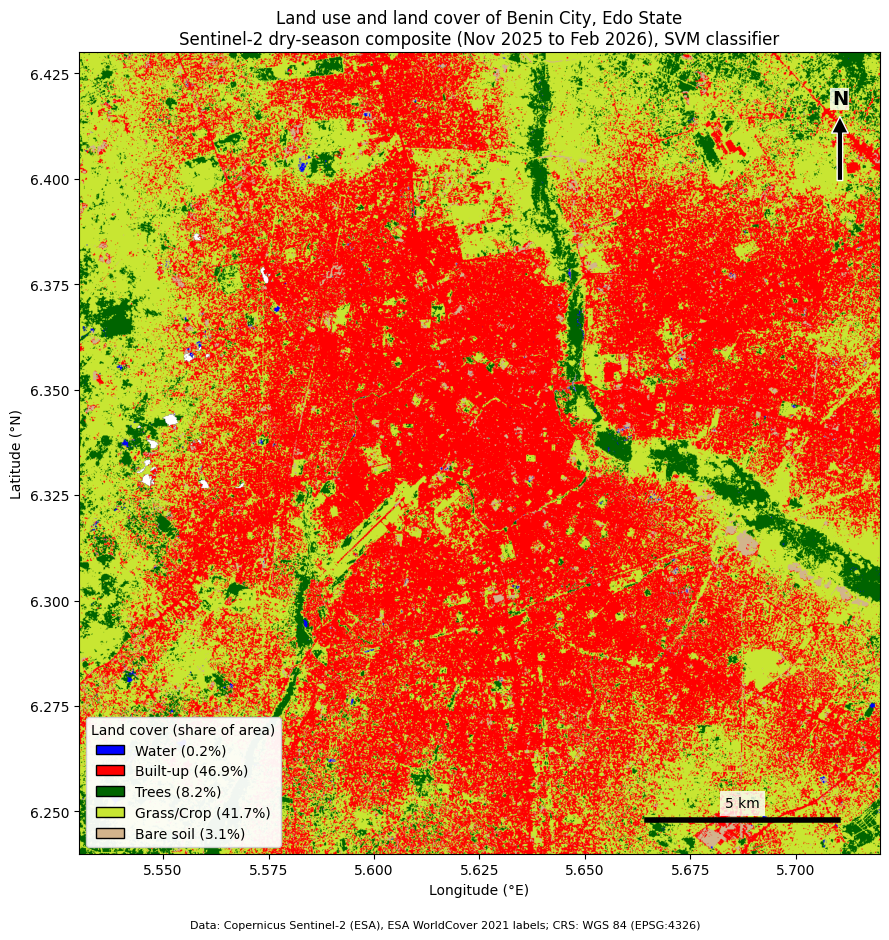

In [ ]:
# Static map with legend, saved as PNG for submission
W, S, E, N = 5.53, 6.24, 5.72, 6.43
url = final.visualize(min=0, max=4, palette=PALETTE).getThumbURL(
    {"region": aoi, "dimensions": 1600, "format": "png"})
lulc_png = Image.open(io.BytesIO(requests.get(url, timeout=300).content))

fig, ax = plt.subplots(figsize=(9, 9.5))
ax.imshow(lulc_png, extent=[W, E, S, N])
ax.set_xlabel("Longitude (°E)")
ax.set_ylabel("Latitude (°N)")
ax.set_title(f"Land use and land cover of {CITY}\n"
             f"Sentinel-2 dry-season composite (Nov 2025 to Feb 2026), {BEST} classifier", fontsize=12)

handles = [Patch(facecolor="#" + c, edgecolor="black", label=f"{n} ({area_table.loc[n, 'Share (%)']:.1f}%)")
           for n, c in zip(NAMES, PALETTE)]
ax.legend(handles=handles, title="Land cover (share of area)", loc="lower left", framealpha=0.95)

# North arrow and 5 km scale bar (1° longitude ≈ 110.6 km at 6.3°N)
ax.annotate("", xy=(0.95, 0.92), xytext=(0.95, 0.84), xycoords="axes fraction",
            arrowprops=dict(facecolor="black", edgecolor="white", width=4, headwidth=12))
ax.text(0.95, 0.935, "N", transform=ax.transAxes, ha="center", fontsize=14, fontweight="bold",
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=1))
deg_5km = 5 / (111.32 * np.cos(np.radians(6.335)))
x0, y0 = E - 0.01 - deg_5km, S + 0.008
ax.plot([x0, x0 + deg_5km], [y0, y0], color="black", lw=4)
ax.text(x0 + deg_5km / 2, y0 + 0.003, "5 km", ha="center", fontsize=10,
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.8))
fig.text(0.5, 0.01, "Data: Copernicus Sentinel-2 (ESA), ESA WorldCover 2021 labels; CRS: WGS 84 (EPSG:4326)",
         ha="center", fontsize=8)

fig.tight_layout(rect=[0, 0.02, 1, 1])
fig.savefig("benin_city_lulc_map.png", dpi=200)
plt.show()

In [ ]:
# Numbers for the write-up below
print(f"Images in composite: {n_images}; samples after checking: {len(df)} "
      f"({(df.split == 'train').sum()} train / {(df.split == 'test').sum()} test)")
print(f"Checking: {int(summary['checked'].sum())} checked, "
      f"{int((log.status == 'corrected').sum())} corrected, {int((log.status == 'removed').sum())} removed")
display(comparison)
for name in results:
    print(name); display(results[name]["per_class"])
display(cv_table)
print("Top 3 features (EE Random Forest):", list(importance.index[:3]))
for name in results:   # biggest off-diagonal confusion per classifier
    c = results[name]["cm"].to_numpy().copy()
    np.fill_diagonal(c, 0)
    t, p = np.unravel_index(c.argmax(), c.shape)
    print(f"{name}: most confused = {NAMES[t]} mapped as {NAMES[p]} ({c.max()} test points)")
display(area_table)

Images in composite: 14; samples after checking: 957 (669 train / 288 test)
Checking: 100 checked, 34 corrected, 7 removed


,Overall accuracy,Kappa,Mean F1
Random Forest,0.819,0.765,0.833
SVM,0.847,0.800,0.852


Random Forest


,Producer's accuracy,User's accuracy,F1
Water,0.973,0.973,0.973
Built-up,0.784,0.725,0.753
Trees,1.000,0.679,0.809
Grass/Crop,0.824,0.854,0.838
Bare soil,0.726,0.869,0.791


SVM


,Producer's accuracy,User's accuracy,F1
Water,0.973,0.973,0.973
Built-up,0.878,0.747,0.807
Trees,0.842,0.762,0.800
Grass/Crop,0.871,0.860,0.865
Bare soil,0.726,0.930,0.815


,Mean accuracy,Std across folds
Random 5-fold CV,0.859,0.031
Spatial 5-fold CV (blocks),0.741,0.174


Top 3 features (EE Random Forest): ['NDVI', 'NDWI', 'B11']
Random Forest: most confused = Bare soil mapped as Built-up (18 test points)
SVM: most confused = Bare soil mapped as Built-up (17 test points)


,Area (km²),Share (%)
Class,,
Water,0.77,0.17
Built-up,207.09,46.93
Trees,35.95,8.15
Grass/Crop,183.84,41.66
Bare soil,13.63,3.09
Total,441.28,100.00


# Interpretation

**Classifier performance.** SVM performed better than Random Forest, with an overall accuracy of 0.847 (kappa 0.800, mean F1 0.852) against 0.819 (kappa 0.765, mean F1 0.833), so the final map was produced with SVM. The difference shows most clearly in the Trees class. Random Forest found every true tree sample (producer's accuracy 1.00) but also labelled many non-tree points as trees (user's accuracy 0.68), so it over-mapped trees, while SVM was more balanced (0.84 and 0.76). After cleaning, Trees had only 62 samples, and SVM, working on scaled features, drew a more even boundary between this small class and Grass/Crop. The most important features were NDVI, NDWI and SWIR (B11).

**Class confusion.** The main confusion was Bare soil mapped as Built-up (17 test points with SVM). In Benin City this is expected, because laterite earth roads, bare compounds and uncompleted buildings reflect much like roofs and concrete in the SWIR bands. Water scored highest (0.97), but this figure is likely inflated: most water samples came from just three small water bodies, so test points sat beside training points in the same pond.

**Spatial validation.** Random cross-validation gave 0.859, but spatial cross-validation gave 0.741, about 12 percentage points lower. Its large spread across folds (±0.174) shows that accuracy varies strongly between parts of the city, partly because some classes, such as water and bare soil, were sampled from only a few locations. The spatial figure is the more honest estimate for unseen areas.

**Land cover.** Built-up covers 207.1 km² (46.9%) of the 441 km² study area and forms a dense core in the centre of the city, surrounded by Grass/Crop (183.8 km², 41.7%) on the urban fringe. Trees (36.0 km², 8.2%) occur mainly as belts along the river corridors, while Bare soil (3.1%) and Water (0.2%) are small.

**Limitations**
1. **Training labels.** WorldCover 2021 labels were poor for Benin City in 2025–26. Of the 100 samples I checked, 41 were wrong or unusable, including 19 of 20 Trees (mostly grassland, bare ground or rooftops). I corrected 34, removed 7, and removed 536 unchecked samples whose NDVI or MNDWI disagreed with their label. Because the same indices were then used as features, the reported accuracies are probably somewhat optimistic.
2. **Mixed pixels and similar surfaces.** At 10 to 20 m, many pixels mix roofs, trees, grass and bare ground, and bare laterite surfaces are spectrally close to built-up areas.
3. **Season and cloud.** The single dry-season composite of 14 images was affected by Harmattan haze, which makes dry grassland and scattered trees harder to separate, and a few small patches in the west remain unclassified where cloud was masked in every image.